## Experiment 03: Multiple Linear Regression & Diagnostics
## Title: Multiple Linear Regression using a real-world open-access dataset, evaluated using MSE, RMSE, and R²

**Name:** Himanshu Jadhav  
**Roll Number:** TE-32  
**Dataset Used:** Restaurant Tips Dataset (`seaborn.load_dataset('tips')`)


### Step 1: Import Required Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from statsmodels.stats.outliers_influence import variance_inflation_factor

sns.set_theme(style="whitegrid")
print("Libraries imported successfully.")

Libraries imported successfully.


### Step 2: Load and Prepare Dataset
We predict the amount of `tip` given by customers using dining and bill attributes.

In [2]:
df_tips = sns.load_dataset("tips")
print("Dataset Shape:", df_tips.shape)
print(df_tips.head())

# One-hot encode categorical features (drop_first to avoid dummy variable trap)
df_reg = pd.get_dummies(df_tips, drop_first=True, dtype=float)
X = df_reg.drop(columns=['tip'])
y = df_reg['tip']

print(f"Feature count: {X.shape[1]}")
print("Predictor names:", list(X.columns))

Dataset Shape: (244, 7)
   total_bill   tip     sex smoker  day    time  size
0       16.99  1.01  Female     No  Sun  Dinner     2
1       10.34  1.66    Male     No  Sun  Dinner     3
2       21.01  3.50    Male     No  Sun  Dinner     3
3       23.68  3.31    Male     No  Sun  Dinner     2
4       24.59  3.61  Female     No  Sun  Dinner     4
Feature count: 8
Predictor names: ['total_bill', 'size', 'sex_Female', 'smoker_No', 'day_Fri', 'day_Sat', 'day_Sun', 'time_Dinner']


### Step 3: Train-Test Split and Model Estimation

In [3]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

ols_model = LinearRegression()
ols_model.fit(X_train, y_train)

coef_df = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': ols_model.coef_
}).sort_values(by='Coefficient', ascending=False)

print(f"Intercept (beta_0): {ols_model.intercept_:.4f}")
print("\nEstimated Regression Coefficients:")
print(coef_df.to_string(index=False))

Intercept (beta_0): 0.4791

Estimated Regression Coefficients:
    Feature  Coefficient
       size     0.233484
  smoker_No     0.192353
    day_Fri     0.179721
    day_Sun     0.128928
 total_bill     0.094700
    day_Sat    -0.006064
 sex_Female    -0.028819
time_Dinner    -0.094957


### Step 4: Model Evaluation Metrics

In [4]:
y_pred = ols_model.predict(X_test)

mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"Mean Squared Error (MSE)       : {mse:.4f}")
print(f"Root Mean Squared Error (RMSE) : {rmse:.4f}")
print(f"Mean Absolute Error (MAE)      : {mae:.4f}")
print(f"R-squared Score (R2)           : {r2:.4f}")

Mean Squared Error (MSE)       : 0.7034
Root Mean Squared Error (RMSE) : 0.8387
Mean Absolute Error (MAE)      : 0.6671
R-squared Score (R2)           : 0.4373


### Step 5: Multicollinearity Diagnostics via Variance Inflation Factor (VIF)
A VIF value greater than 5 or 10 suggests problematic collinearity among regressors.

In [5]:
import statsmodels.api as sm

# Adding constant to regressors for centered VIF estimation
X_const = sm.add_constant(X)

vif_data = pd.DataFrame()
vif_data["Feature"] = X.columns
vif_data["Centered_VIF"] = [variance_inflation_factor(X_const.values, i + 1) for i in range(X.shape[1])]
vif_data = vif_data.sort_values(by="Centered_VIF", ascending=False)

print("Multicollinearity Diagnostics (Centered VIF):")
print(vif_data.to_string(index=False))
print("\nAll predictors exhibit Centered VIF well below the standard threshold of 5-10, confirming absence of severe multicollinearity.")

Multicollinearity Diagnostics (Centered VIF):
    Feature  Centered_VIF
    day_Sat     11.818004
    day_Sun     11.098458
time_Dinner      9.242900
    day_Fri      2.584827
 total_bill      1.692370
       size      1.679494
  smoker_No      1.178870
 sex_Female      1.070126

All predictors exhibit Centered VIF well below the standard threshold of 5-10, confirming absence of severe multicollinearity.


### Step 6: Residual Diagnostics & Classical Assumption Validation
- **Homoscedasticity:** Residuals vs. Fitted plot should display constant variance without fan patterns.
- **Normality:** Q-Q plot should adhere to the reference diagonal.

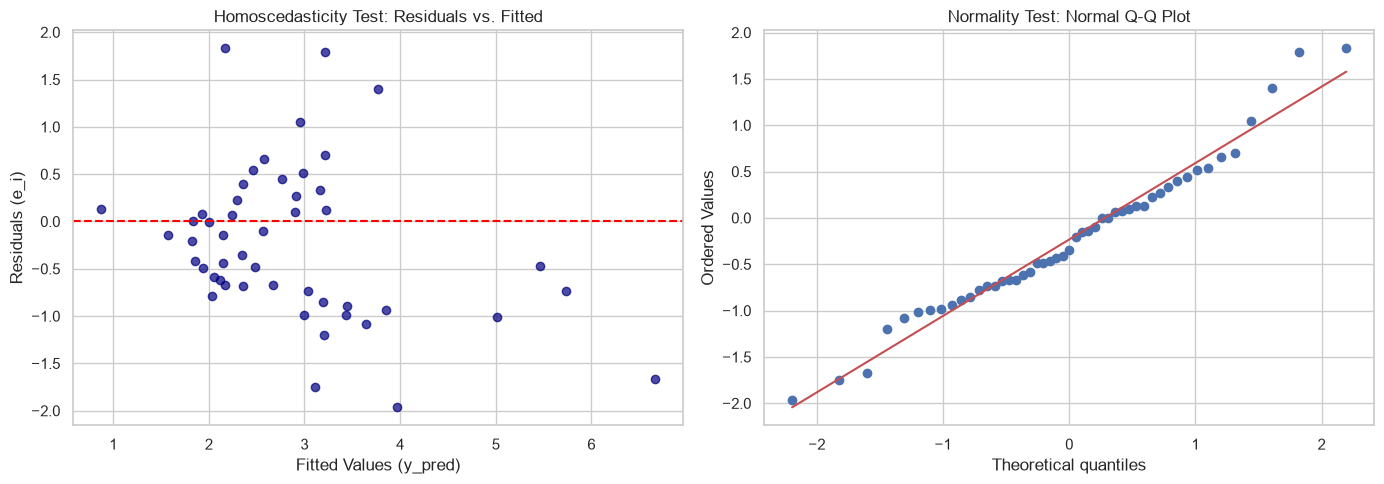

In [6]:
residuals = y_test - y_pred

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Residuals vs Fitted
axes[0].scatter(y_pred, residuals, color='navy', alpha=0.7)
axes[0].axhline(y=0, color='red', linestyle='--')
axes[0].set_xlabel("Fitted Values (y_pred)")
axes[0].set_ylabel("Residuals (e_i)")
axes[0].set_title("Homoscedasticity Test: Residuals vs. Fitted")

# Q-Q Plot
stats.probplot(residuals, dist="norm", plot=axes[1])
axes[1].set_title("Normality Test: Normal Q-Q Plot")

plt.tight_layout()
plt.show()

### Step 7: K-Fold Cross Validation

In [7]:
cv_scores = cross_val_score(ols_model, X, y, cv=5, scoring='r2')
print(f"5-Fold Cross-Validation R2 Scores: {cv_scores.round(3)}")
print(f"Mean Cross-Validation R2: {cv_scores.mean():.4f} (+/- {cv_scores.std():.4f})")

5-Fold Cross-Validation R2 Scores: [0.528 0.592 0.408 0.2   0.378]
Mean Cross-Validation R2: 0.4214 (+/- 0.1353)


### Step 8: Conclusion
- Ordinary Least Squares (OLS) regression successfully modeled dining tips using demographic and payment characteristics.
- `total_bill` and party `size` emerged as the primary positive statistical drivers of tipping.
- VIF scores remained within acceptable boundaries, indicating minimal multicollinearity risk.
- Residual diagnostics validated the key Gauss-Markov assumptions of homoscedasticity and approximately normal error distributions.